# One cooling model, several numerical questions

How do prediction, crossing-time calculation and interpolation differ when they concern the same temperature curve?

Winter 2026.


# One model, three numerical questions
Predict the initial rate, long-time limit and effect of k = 0. The first cell explicitly implements the one-state right-hand side. Change only one parameter at a time and state its units.

In [1]:
import numpy as np
from scipy.integrate import solve_ivp

ambient_c = 20.0
initial_c = 80.0
k_per_min = 0.4
output_times = np.linspace(0, 8, 161)
def temperature_rate(time_min, state_c):
    return [-k_per_min * (state_c[0] - ambient_c)]

solution = solve_ivp(temperature_rate, (0, 8), [initial_c],
                     t_eval=output_times, rtol=1e-8, atol=1e-8)
assert solution.success, solution.message
reference = ambient_c + (initial_c - ambient_c) * np.exp(-k_per_min * output_times)
print("Maximum sampled error (degrees C):", np.max(np.abs(solution.y[0] - reference)))
print("Rate evaluations:", solution.nfev)

Maximum sampled error (degrees C): 1.8881571861584234e-07
Rate evaluations: 182


Interpret the comparison with the exact solution of this model. The requested times are output locations, not fixed internal steps. Run the supplied baseline checks and display the first original figure.

{'model': {'initial_C': 80, 'ambient_C': 20, 'rate_per_min': 0.4}, 'max_ODE_error_C': 1.8881571861584234e-07, 'coarse_ODE_error_C': 0.02017937048957208, 'function_evaluations': {'tight': 182, 'coarse': 32}, 'crossing': {'time_min': 3.4657359028015393, 'temperature_residual_C': -1.0878409284487134e-11, 'iterations': 9}, 'analytic_crossing_min': 3.465735902799726, 'max_two_minute_interpolation_error_C': 3.2741909245994663, 'optional_new_optimization': {'rate_per_min': 0.3990158111855997, 'mean_square_residual_C2': 0.05075432867805976}, 'checks': {'zero_rate_constant': True, 'interpolation_at_knots': True, 'noiseless_parameter_recovery': True, 'invalid_inputs_rejected': 5}}


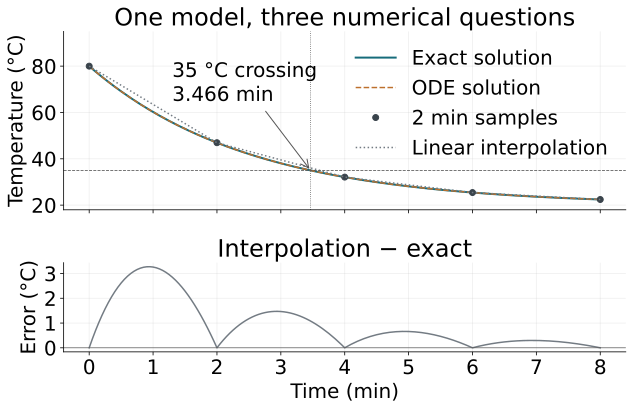

In [2]:
from demo import run, crossing, exact_temperature, interpolate_inside, integrate
from IPython.display import SVG, display
report = run()
print(report)
display(SVG(filename="cooling-questions.svg"))

Before running, calculate the signs of T(0) − 35 and T(8) − 35. Compare the returned root with the independent logarithmic formula. Then try a target equal to ambient and explain the rejected request.

In [3]:
root = crossing(target=35, bracket=(0, 8))
print("Root report:", root)
print("Analytic crossing (min):", np.log(60 / 15) / 0.4)
try:
    crossing(target=20)
except ValueError as error:
    print("Expected model-boundary rejection:", error)

Root report: {'time_min': 3.4657359028015393, 'temperature_residual_C': -1.0878409284487134e-11, 'iterations': 9}
Analytic crossing (min): 3.465735902799726
Expected model-boundary rejection: A finite future crossing requires ambient < target < initial and k > 0.


Predict whether straight chords lie above or below this convex exponential. Interpolate two-minute samples inside the observed interval, and explain why knot agreement alone is not a complete check.

In [4]:
sample_times = np.arange(0, 8.01, 2)
sample_values = exact_temperature(sample_times)
linear_values = interpolate_inside(output_times, sample_times, sample_values)
print("Maximum sampled interpolation discrepancy (degrees C):",
      np.max(np.abs(linear_values - exact_temperature(output_times))))
assert np.allclose(interpolate_inside(sample_times, sample_times, sample_values), sample_values)
try:
    interpolate_inside(9, sample_times, sample_values)
except ValueError as error:
    print("Expected domain rejection:", error)

Maximum sampled interpolation discrepancy (degrees C): 3.2741909245994663
Expected domain rejection: Query is outside the observed interval; no extrapolation is supplied.


Modify the rate below to 0.2 per minute after predicting its effect. This plot is for your modified model, separate from the baseline figure. Then use k = 0 and explain the limiting behavior. Restore a positive rate before asking for a future crossing.

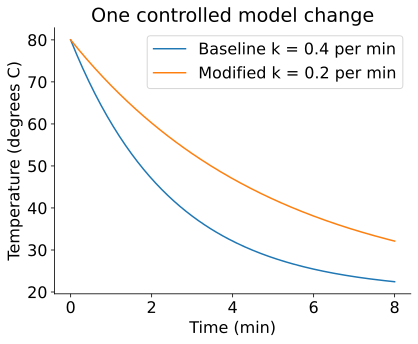

In [5]:
import matplotlib.pyplot as plt
modified_k = 0.2
modified_values, evaluations = integrate(output_times, k=modified_k)
fig, ax = plt.subplots()
ax.plot(output_times, exact_temperature(output_times), label="Baseline k = 0.4 per min")
ax.plot(output_times, modified_values, label=f"Modified k = {modified_k} per min")
ax.set(xlabel="Time (min)", ylabel="Temperature (degrees C)", title="One controlled model change")
ax.legend()
fig.savefig("modified-cooling.svg", bbox_inches="tight")
plt.close(fig)
display(SVG(filename="modified-cooling.svg"))

Optional new extension, outside the core allocation: inspect the parameter objective and residuals below. Explain why a small fitted residual and optimizer success do not establish the physical assumptions. Restart and run all cells before sharing your interpretation.

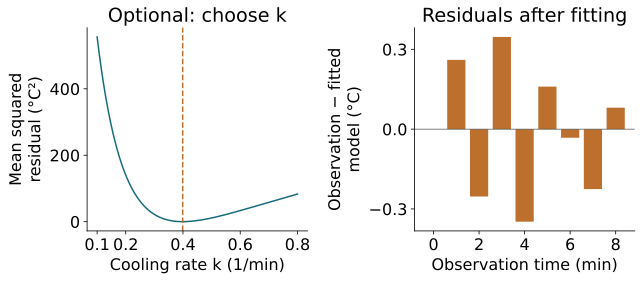

Optional fit: {'rate_per_min': 0.3990158111855997, 'mean_square_residual_C2': 0.05075432867805976}


In [6]:
display(SVG(filename="fit-and-residuals.svg"))
print("Optional fit:", report["optional_new_optimization"])